In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)



In [78]:
data = pd.read_csv('housing.csv' , na_values='?')
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [79]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [80]:
data.duplicated().sum()

np.int64(0)

In [81]:
df_clean = (data.drop(columns=['ocean_proximity'])
            .dropna()
            .reset_index(drop=True))

In [82]:
df_clean.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0


In [83]:
TARGET = 'median_house_value'
quantitative_features = ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

In [84]:
quantitative_features

['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income']

In [85]:
cols = quantitative_features + [TARGET]

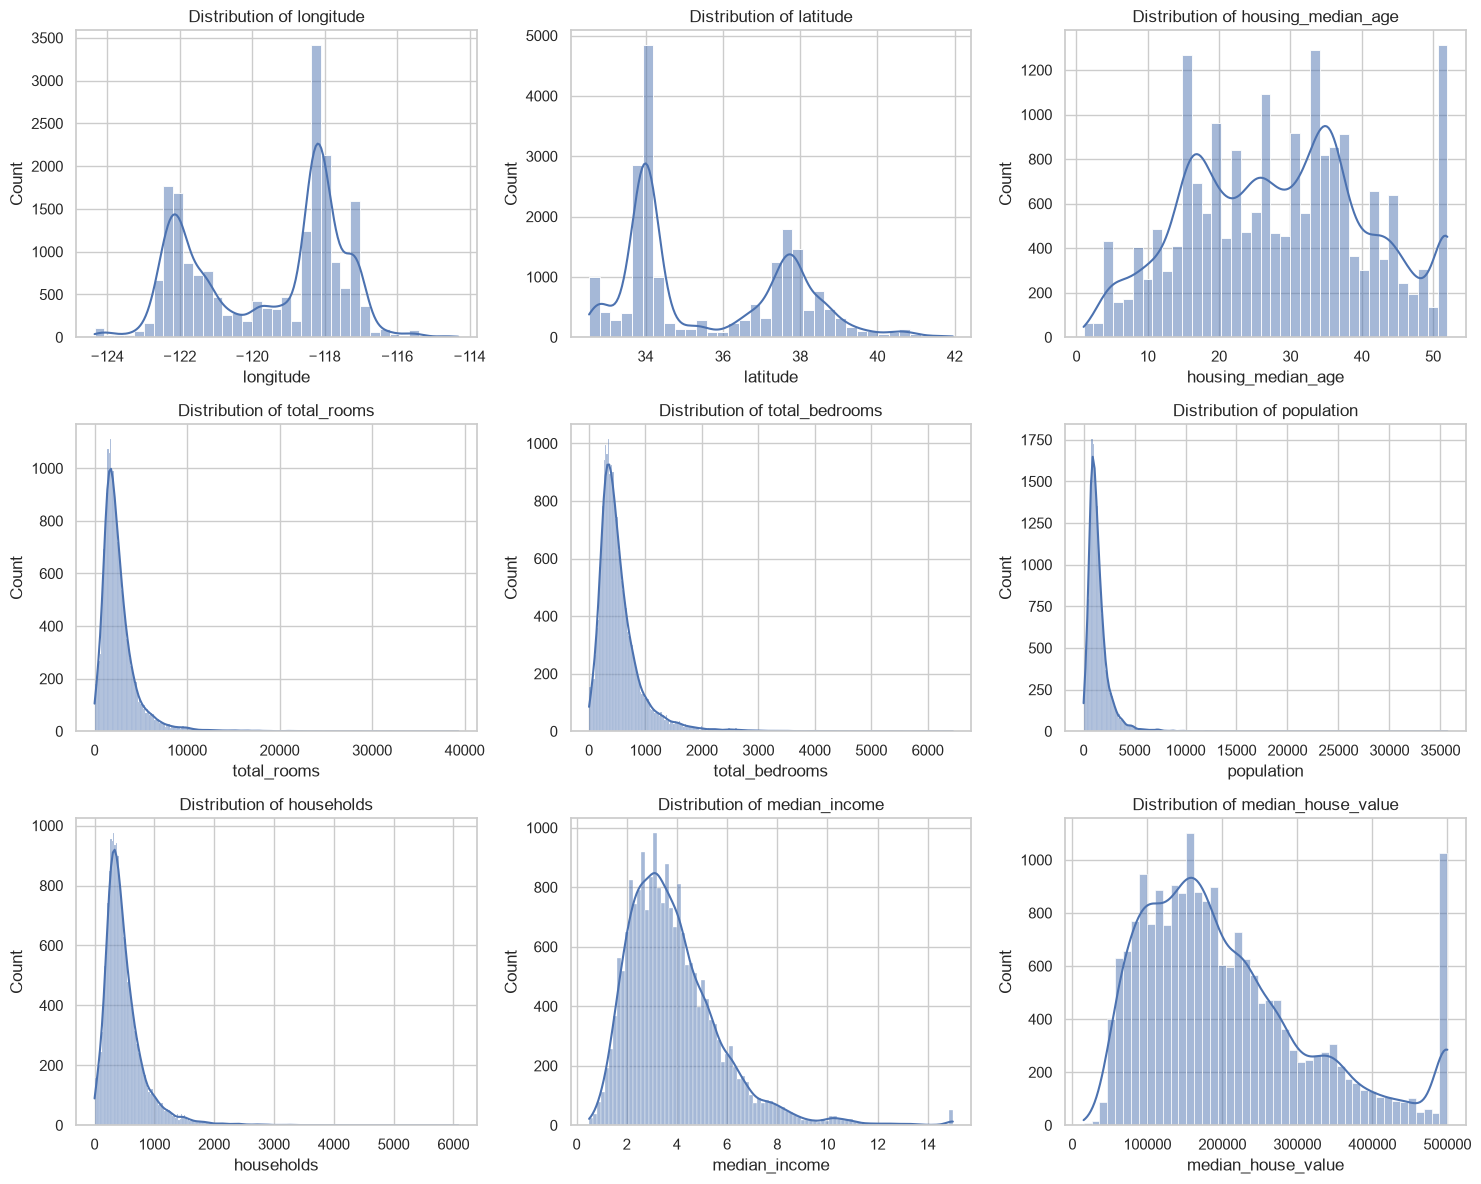

In [86]:
fig, axes = plt.subplots(3,3, figsize=(15, 12))
axes = axes.ravel()
for i, c in enumerate(cols):
    sns.histplot(df_clean[c], ax=axes[i], kde=True)
    axes[i].set_title(f'Distribution of {c}')
plt.tight_layout()
plt.show()

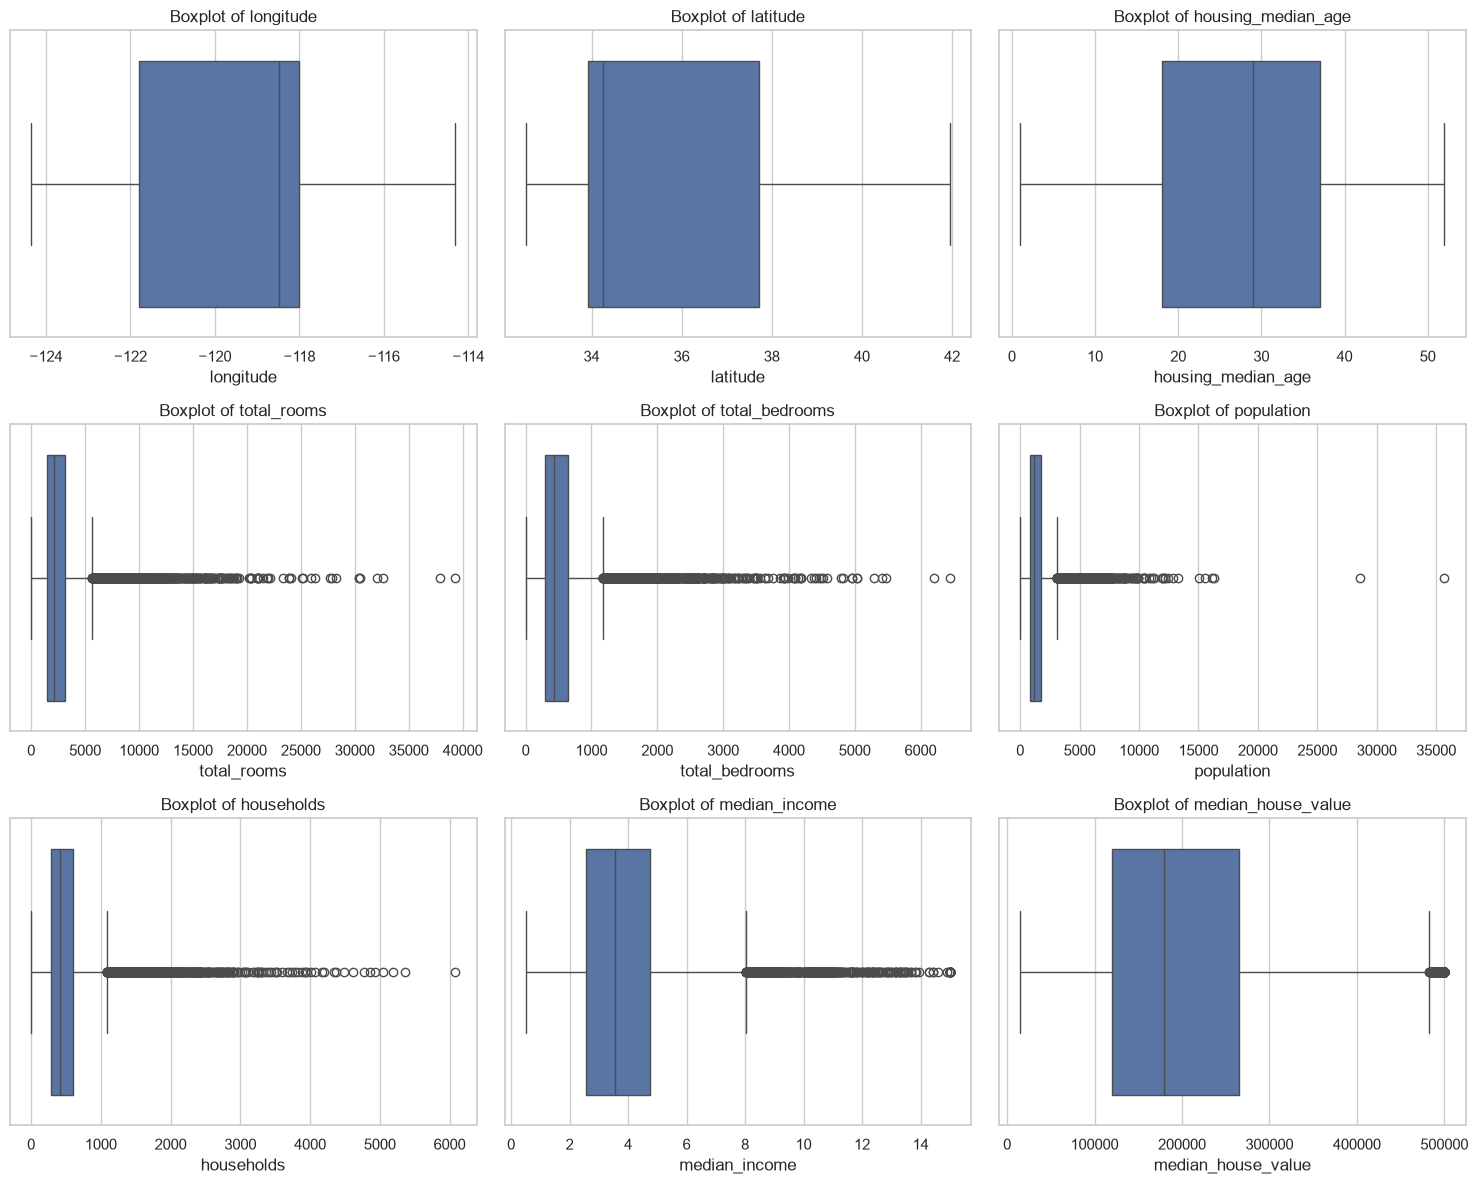

In [87]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()
for i, c in enumerate(cols):
    sns.boxplot(x=df_clean[c], ax=axes[i])
    axes[i].set_title(f'Boxplot of {c}')
plt.tight_layout()
plt.show()

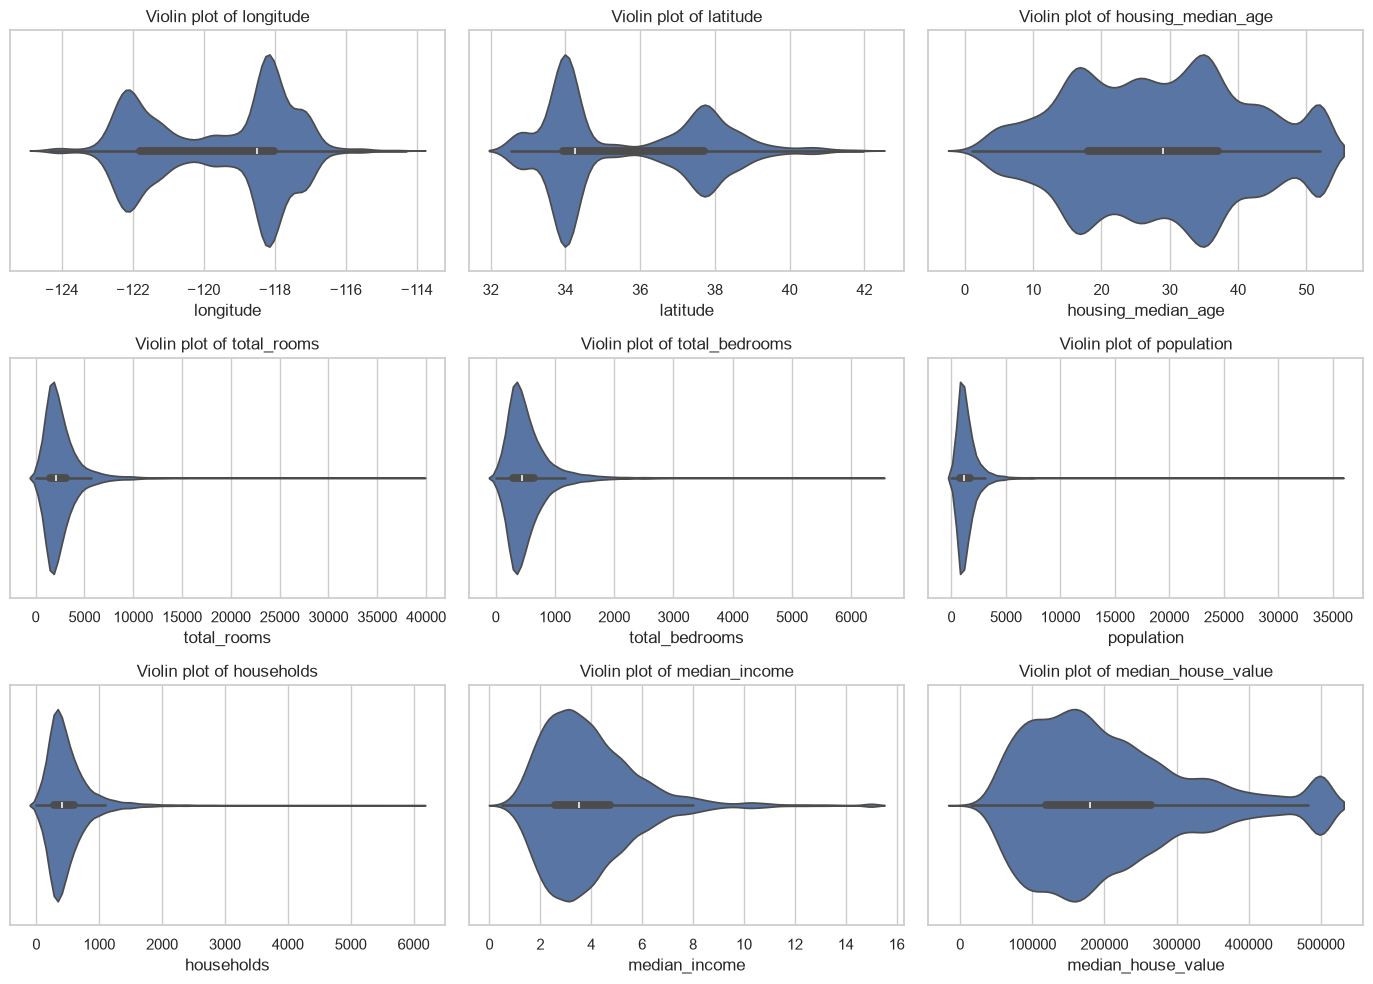

In [88]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.ravel()
for i, c in enumerate(cols):
    sns.violinplot(x=df_clean[c], ax=axes[i])
    axes[i].set_title(f'Violin plot of {c}')
plt.tight_layout()
plt.show()

In [ ]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k*iqr, q3 + k*iqr

mask = pd.Series(True, index=df_clean.index)
for c in quantitative_features:
    lo, hi = iqr_bounds(df_clean[c])
    mask &= df_clean[c].between(lo, hi)

df4 = df_clean[mask]





df4

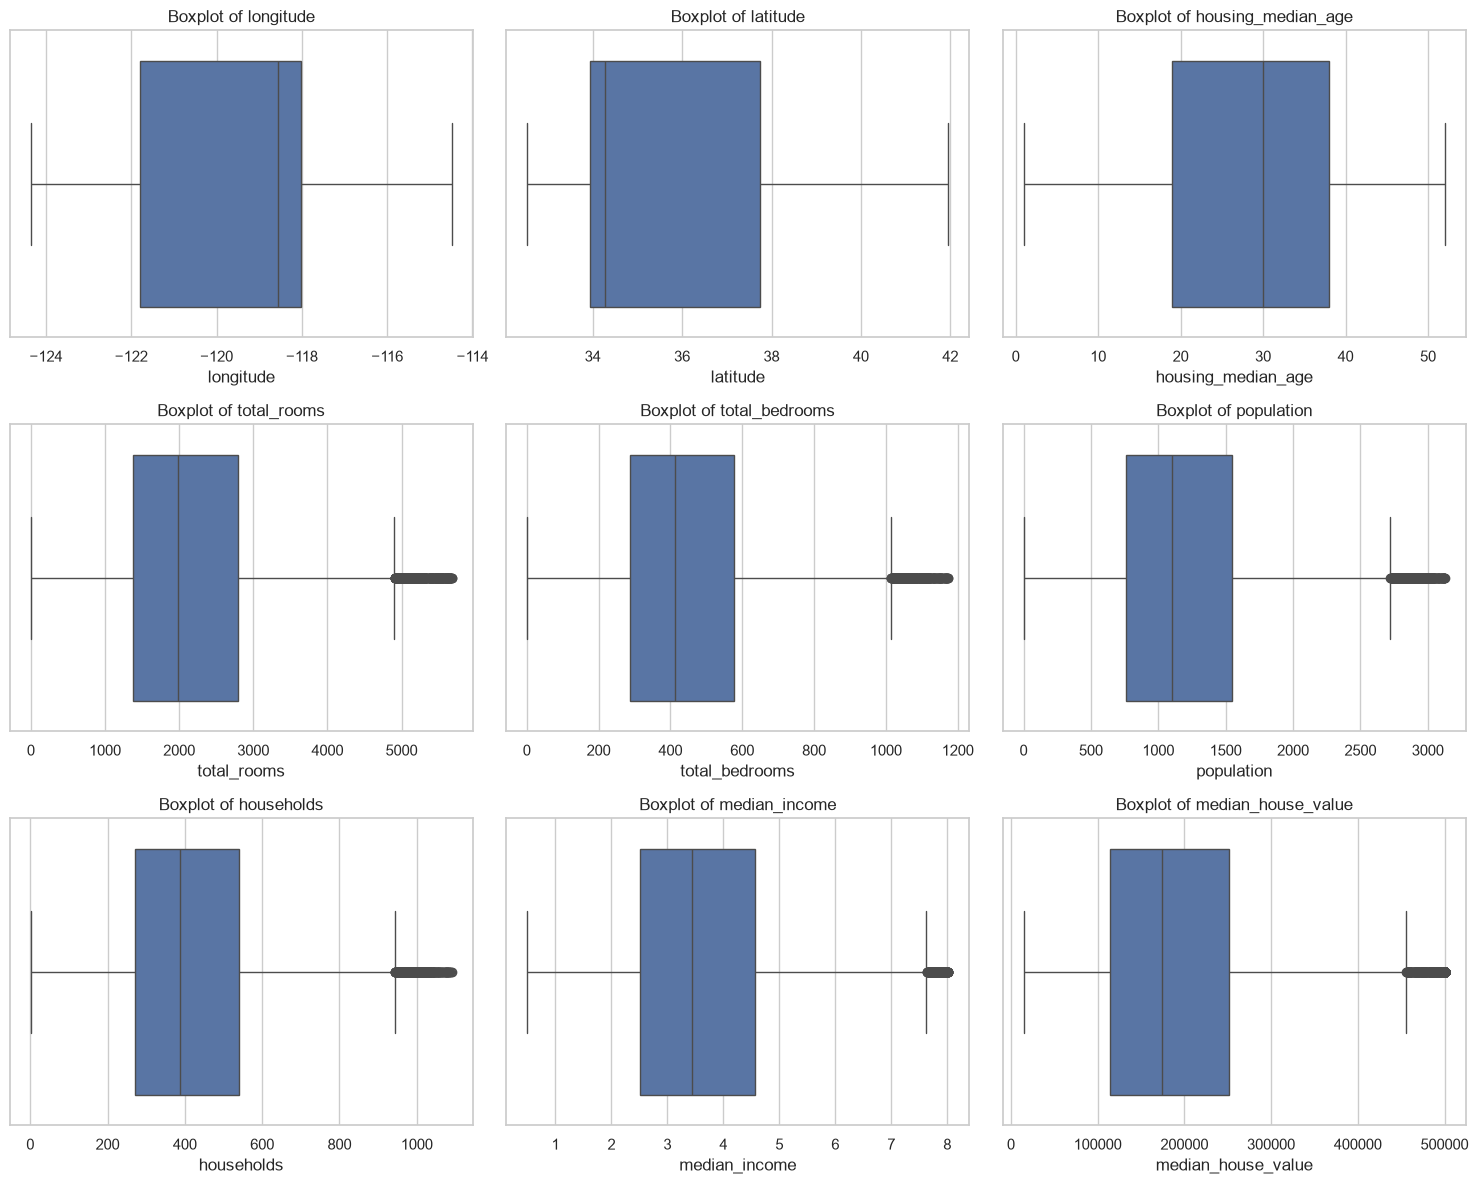

In [92]:

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()
for i, c in enumerate(df4.columns):
    sns.boxplot(x=df4[c], ax=axes[i])
    axes[i].set_title(f'Boxplot of {c}')
plt.tight_layout()
plt.show()

In [93]:
df_clean = df4.copy()

In [94]:
df_clean.skew()


longitude            -0.274809
latitude              0.437105
housing_median_age    0.008018
total_rooms           0.649527
total_bedrooms        0.638059
population            0.636057
households            0.589965
median_income         0.576890
median_house_value    0.997900
dtype: float64

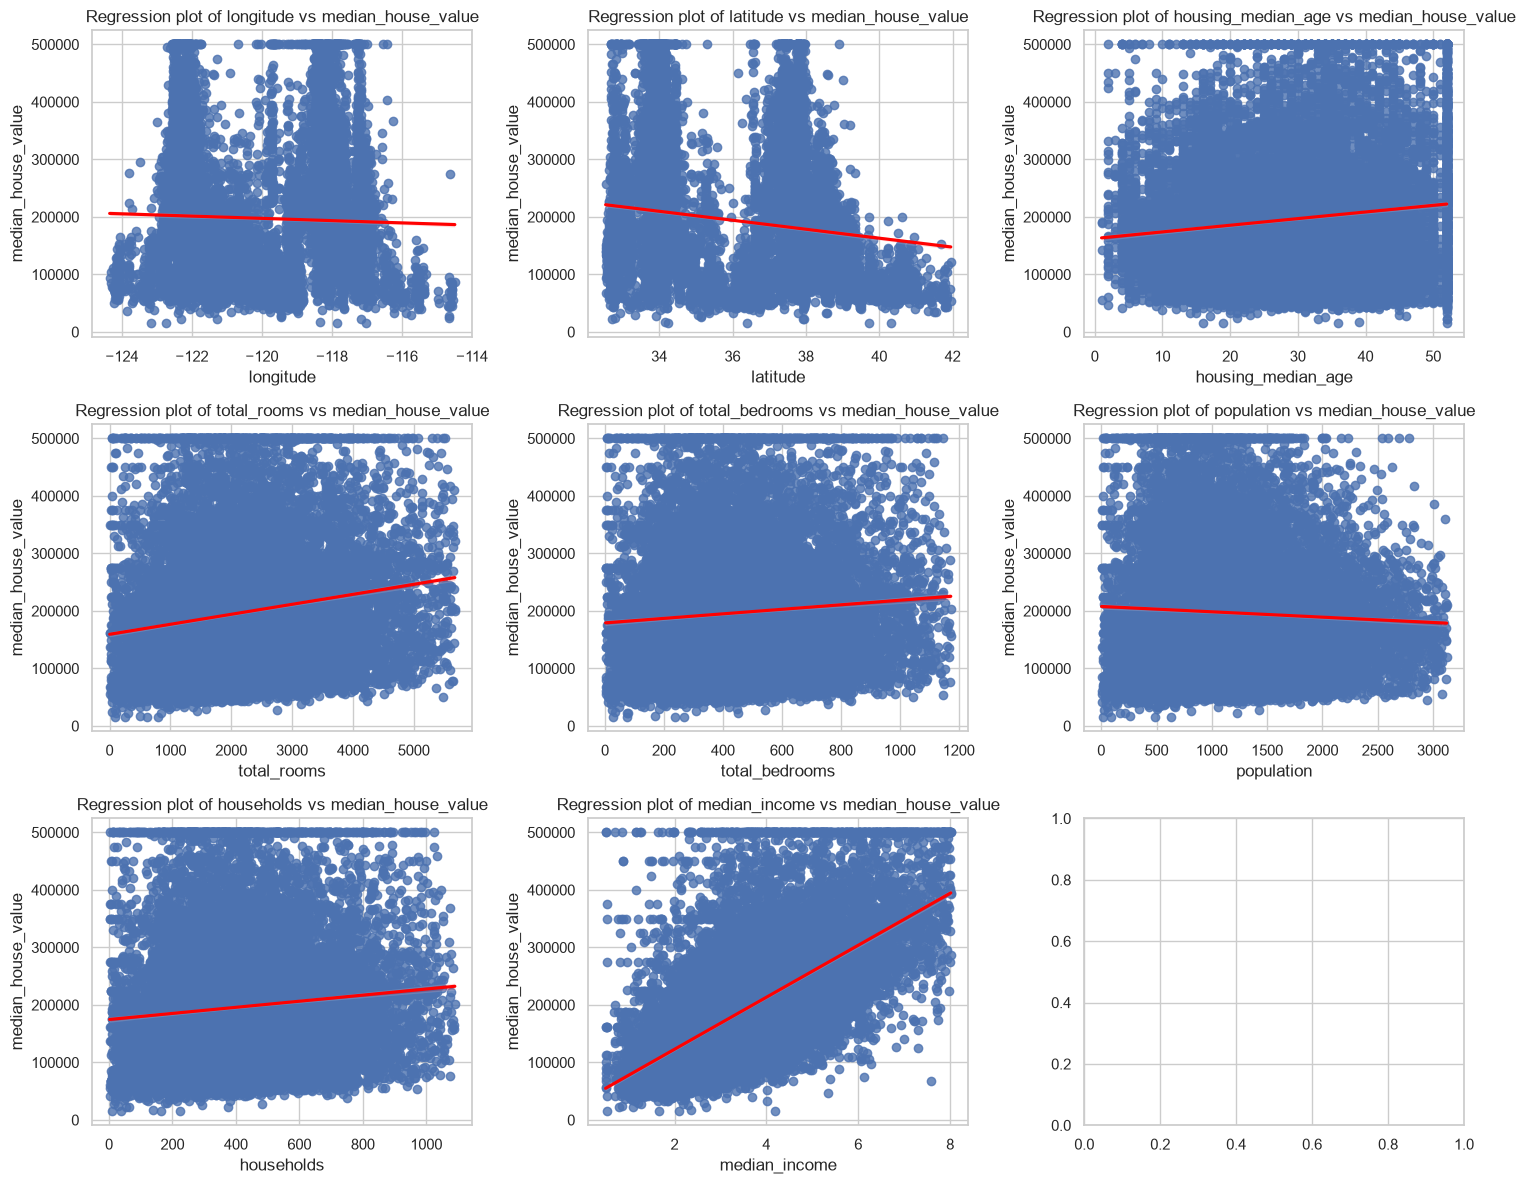

In [95]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()
for i, c in enumerate(quantitative_features):
    sns.regplot(x=c, y=TARGET, data=df_clean, ax=axes[i], line_kws={'color': 'red'})
    axes[i].set_title(f'Regression plot of {c} vs {TARGET}')
plt.tight_layout()
plt.show()

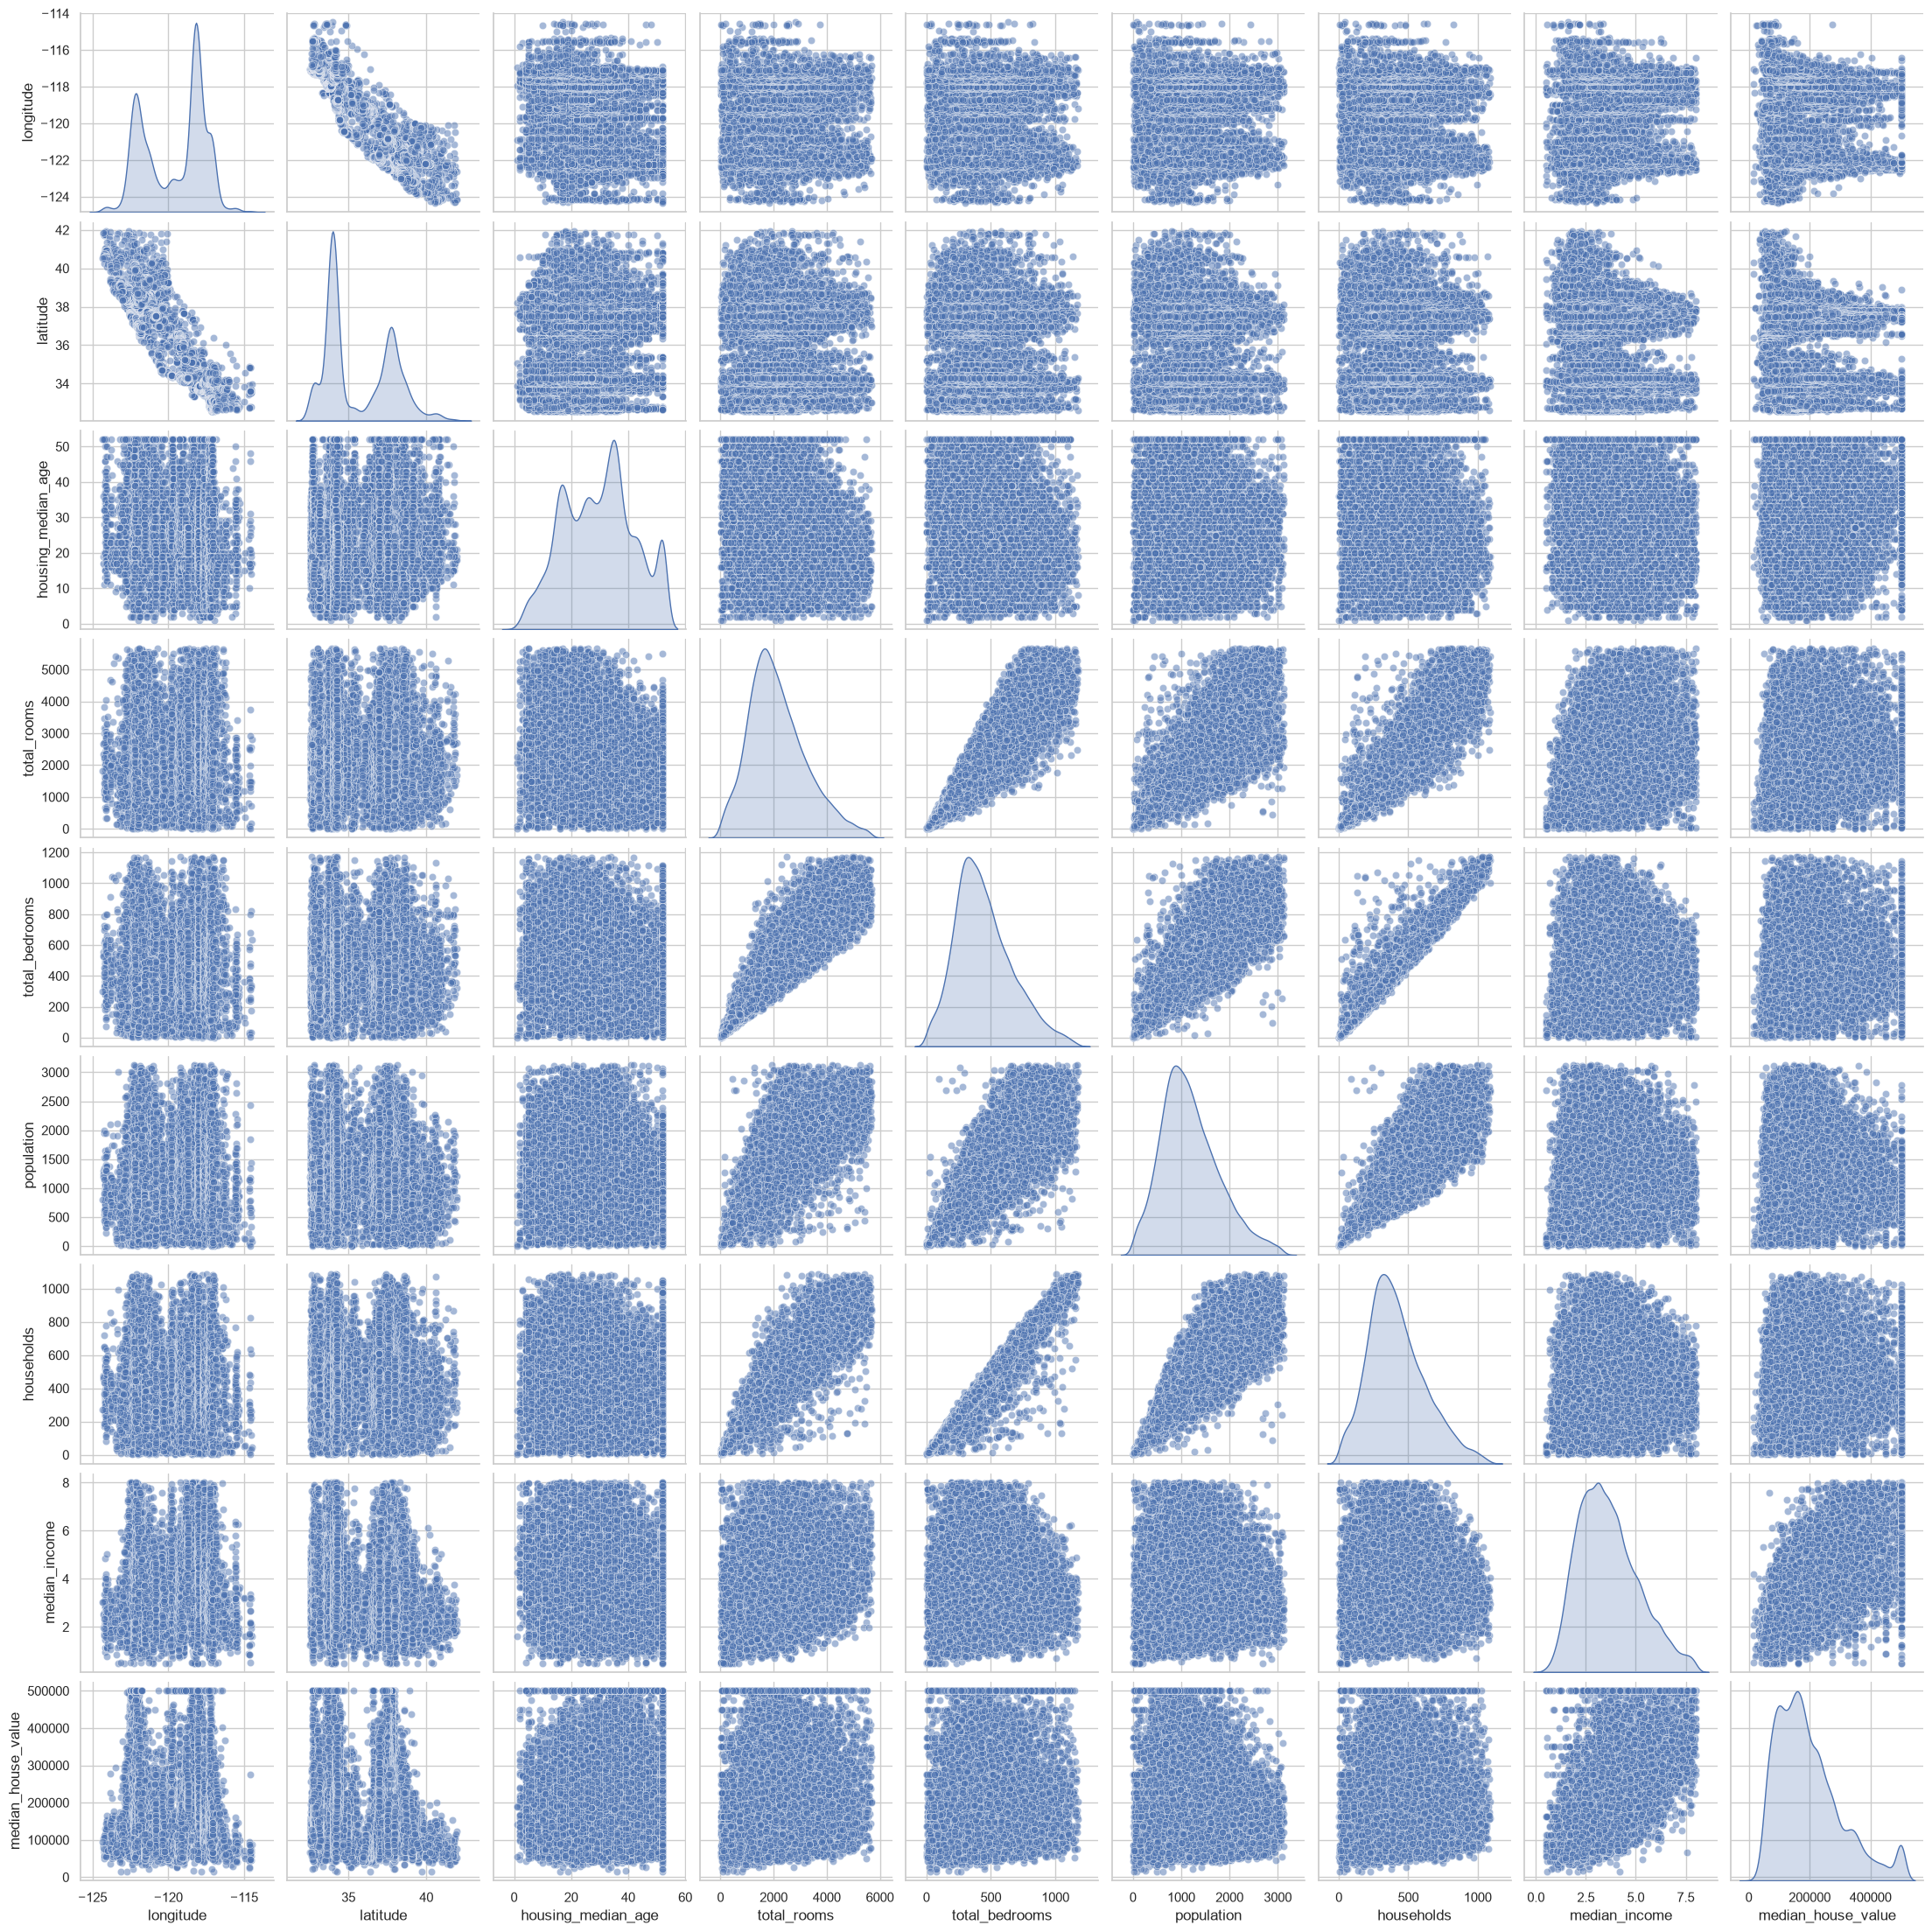

In [96]:
sns.pairplot(df_clean[quantitative_features + [TARGET]], diag_kind='kde', plot_kws={'alpha': 0.5})

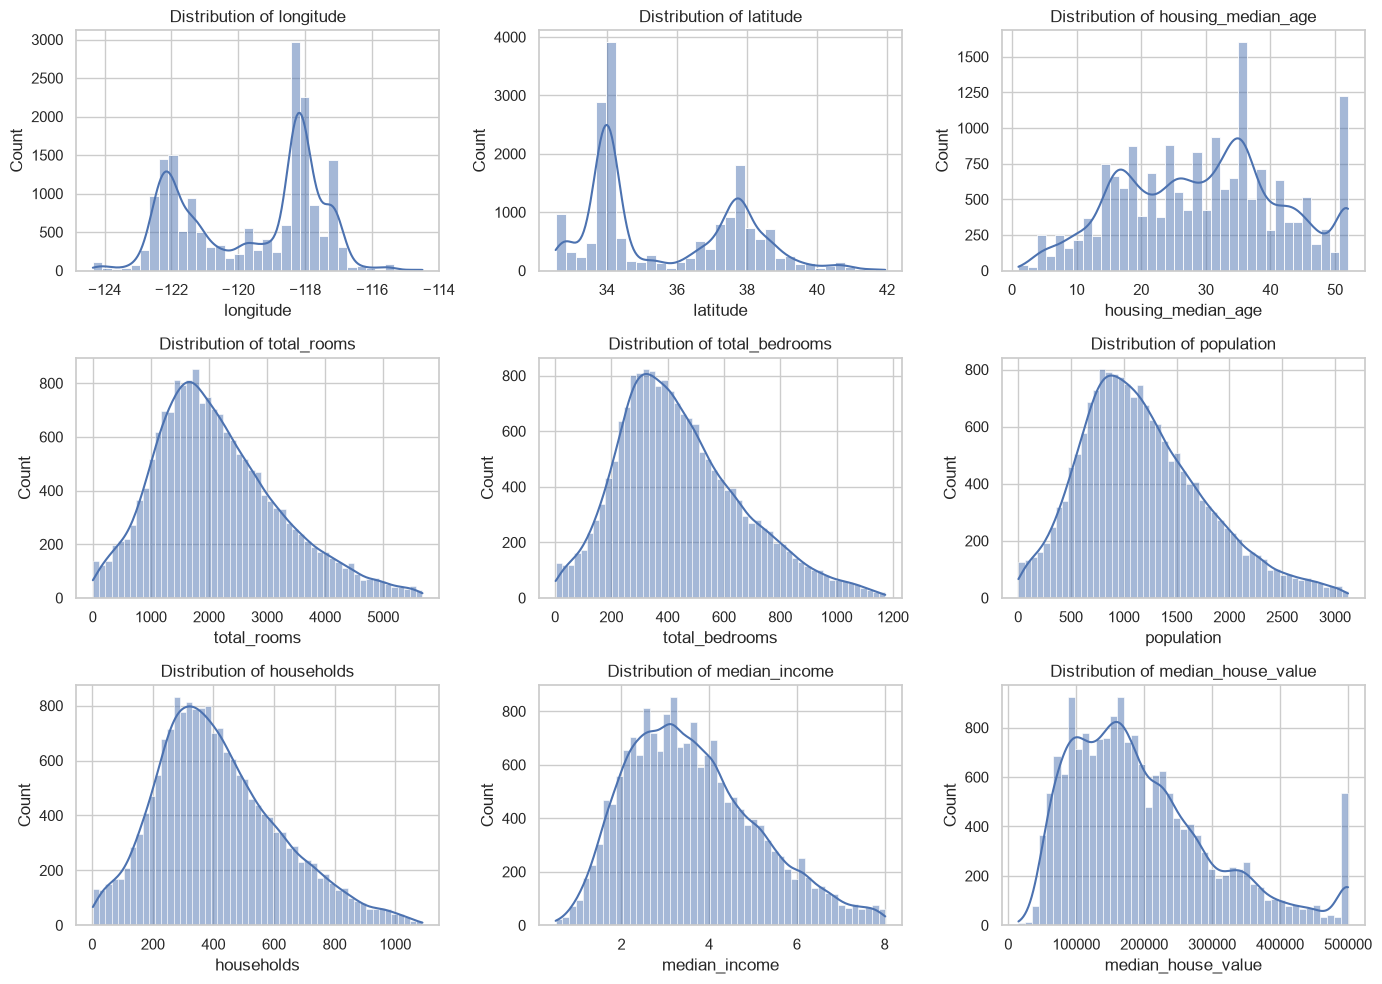

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.ravel()
for i, feature in enumerate(df4.columns):
    sns.histplot(df_clean[feature], ax=axes[i], kde=True)
    axes[i].set_title(f'Distribution of {feature}')
plt.tight_layout()
plt.show()


fig ,axes  = plt.subplot


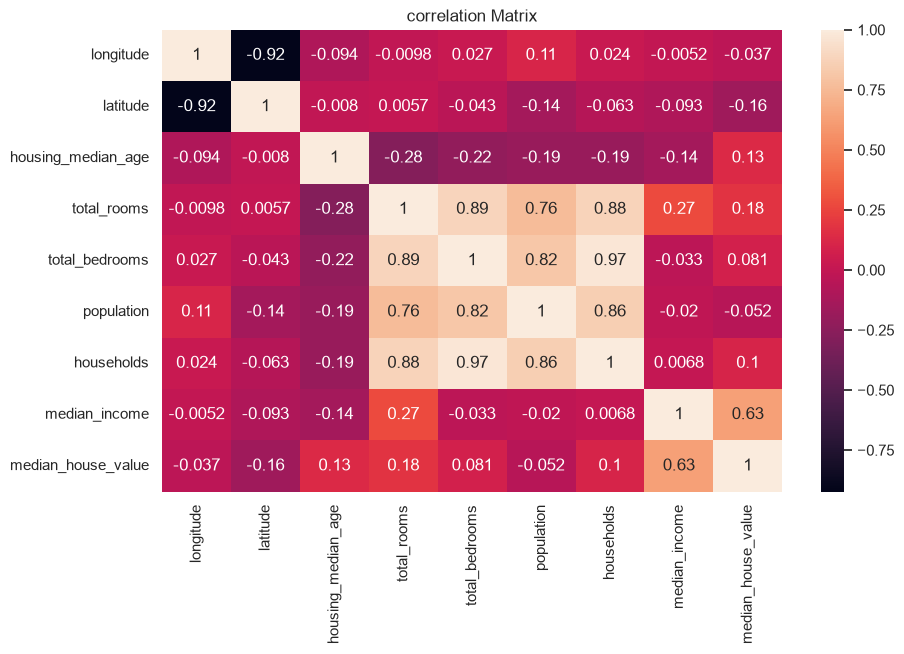

In [98]:
plt.figure(figsize=(10, 6))
corr = df_clean.corr()
sns.heatmap(corr,annot=True)
plt.title("correlation Matrix")
plt.show()

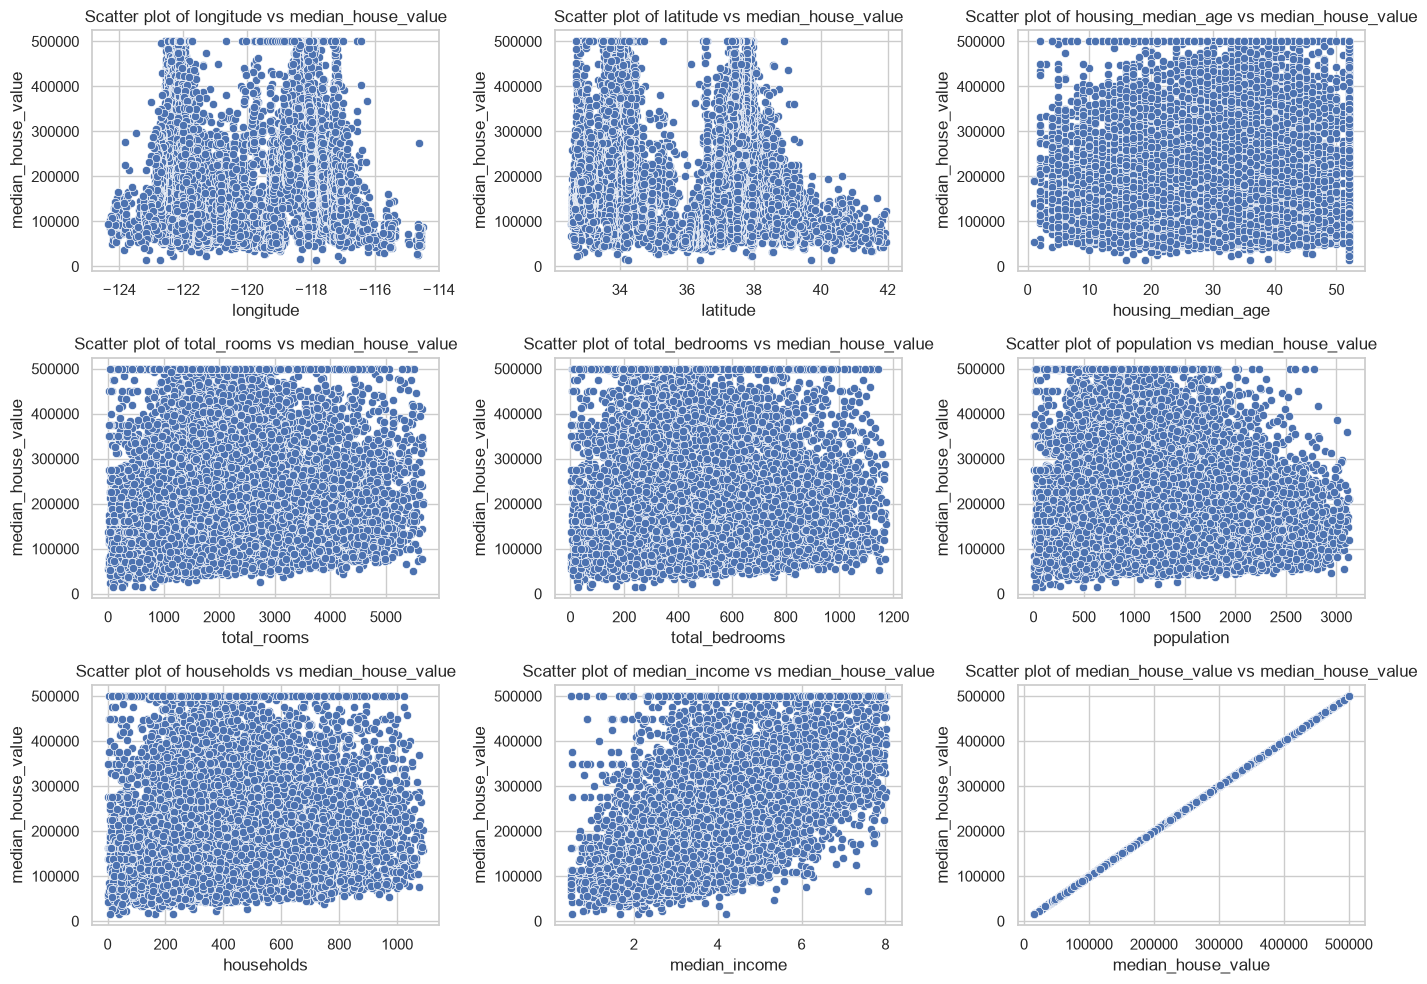

In [ ]:
fig, axes = plt.subplots(3,3, figsize=(14,10))
axes = axes.ravel()
for i, c in enumerate(df_clean):
    sns.scatterplot(data=df_clean,x=c,y=TARGET,ax=axes[i])
    axes[i].set_title(f'Scatter plot of {c} vs {TARGET}')
plt.tight_layout()
plt.show()

In [99]:
X = df_clean[quantitative_features]
Y = df_clean[TARGET]

In [104]:
train_X,test_X,train_Y,test_Y=train_test_split(X,Y, train_size=0.7,test_size=0.3,random_state=RANDOM_STATE)

In [105]:
model = LinearRegression()
model.fit(train_X,train_Y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[-38729.64,-39082.09, 1224.98,..., -72.71, 77.02, 46786.81]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['longitude','latitude','housing_median_age',...,'population','households', 'median_income']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-3.255e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [108]:
model.coef_.tolist()

[-38729.641212801835,
 -39082.09467531001,
 1224.9845063544192,
 -25.492711057490787,
 259.63255296911234,
 -72.70935926048864,
 77.0211617471767,
 46786.813781455436]

In [110]:
model.intercept_

np.float64(-3254735.6492533004)

In [111]:
coefficiant = pd.DataFrame({'feature':quantitative_features,'coefficiaent':model.coef_})

In [112]:
coefficiant

,feature,coefficiaent
0,longitude,-38729.641213
1,latitude,-39082.094675
2,housing_median_age,1224.984506
3,total_rooms,-25.492711
4,total_bedrooms,259.632553
5,population,-72.709359
6,households,77.021162
7,median_income,46786.813781


In [113]:
y_pred = model.predict(test_X)
y_pred

array([121517.58205186, 165645.80550556, 190428.65951183, ...,
       138536.80400097,  75794.53100484, 303819.73079313], shape=(5399,))

In [114]:
eval = rmse(test_Y,y_pred)
eval

np.float64(67734.97191894584)

In [115]:
mse = mean_squared_error(test_Y, y_pred)
mse

4588026420.860381

In [117]:
mae = mean_absolute_error(test_Y, y_pred)
mae

mae = mean_absolute_error(test_Y,y_pred)
mae

49495.975131928135